# 05 – Automated Hybrid Watering Experiment

## Scientific Context

### Run 20260623_232016 (23:20, T=51°C, soil moisture 25.5%)

**New channel setup (first use):**
| Channel | Coupling | Position |
|---------|----------|----------|
| CH1 | 820 kΩ passive | Pot rim ~3 cm (EM reference) |
| CH3 | Amplifier + 820 kΩ | Soil near plant (primary sensor) |
| CH4 | Amplifier + 820 kΩ | Steel rod beside plant |

**Conditions:** Plant under extreme heat stress (T=51°C, daily max 54°C).
Soil moisture 25.5% (well below threshold 30%). Optimal AE conditions.

### Main finding: +21.7 dB at 3.8 kHz on CH3 after watering

The soil sensor (CH3, earth) shows a significant energy increase in the 3–5 kHz band
after watering. This frequency was already identified in the pilot snapshot as the
strongest peak on CH3+CH4 (27–29 dB prominence).

**Possible causes:**
1. Darcy water flow through soil capillaries (typically 1–10 kHz)
2. Mechanical substrate expansion on water contact
3. Xylem cavitation recovery after rehydration (less likely at 3.8 kHz)

**CH1 (rim, passive):** ±44 dB variation at 24.7–25.0 kHz — not an energy change
but a slight frequency shift of the 25 kHz peak. EM artefact or mechanical
coupling via the pot rim.

**CH4 (steel rod):** −19.5 dB at 19.5 kHz — unclear cause; possibly changed
mechanical coupling due to substrate swelling during watering.

### Limitations

- Only 3 frames per condition (n=3) → low statistical power
- Frequencies >100 kHz (131, 203, 228 kHz) are aliasing artefacts
- No blind run (watering without plant) as reference
- First use of new setup — calibration not yet complete


## References

Full source list: [`../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md`](../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md)

Key references for this notebook:
- Khait et al. (2023): plant acoustic emission under stress — frequency bands for watering-related signals
- Zweifel & Zeugin (2008): drought-induced xylem cavitation — context for post-watering AE changes
- De Roo et al. (2016): cavitation AE in xylem — expected spectral morphology of plant events
- Oletic et al. (2020): continuous AE monitoring hardware — rolling-monitor methodology


## 1. Setup

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd

# set matplotlib backend before all module imports (watering.py imports plt internally)
%matplotlib inline
import matplotlib.pyplot as plt

CHARACTERIZATION_ROOT = Path(
    "/media/christoph/some_space/Nextcloud/hs-augsburg"
    "/Semester_6/Projekt_I1/projekt_i1/src/characterization"
)
if str(CHARACTERIZATION_ROOT) not in sys.path:
    sys.path.insert(0, str(CHARACTERIZATION_ROOT))

from plant_ae.watering import (
    load_condition_signals,
    match_condition_peaks,
    CHANNEL_LABELS,
    CHANNEL_COLORS,
    MAX_FREQUENCY_HZ,
)

HYBRID_DATA_ROOT = CHARACTERIZATION_ROOT / "data" / "hybrid_watering_experiment"
OUTPUT_DIR = (CHARACTERIZATION_ROOT / "data" / "reports" / "notebooks"
              / "05_automated_hybrid_experiment" / "20260622_224324")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUN_ID      = "20260622_224324"
run_dir     = HYBRID_DATA_ROOT / RUN_ID
pre_dir     = run_dir / "snapshot_pre_watering"
watering_dir = run_dir / "snapshot_watering_event"
post_dir    = run_dir / "snapshot_post_watering"

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

manifest = json.loads((run_dir / "hybrid_manifest.json").read_text())
s = manifest["verified_scope_settings"]
dur_min = (
    (pandas_ts := lambda t: __import__("datetime").datetime.fromisoformat(t))
    and (pandas_ts(manifest["finished_utc"]) - pandas_ts(manifest["started_utc"])).seconds / 60
)
print(f"Run ID  : {RUN_ID}")
print(f"Profile : {s['profile']}  {s['sample_rate_hz']/1e3:.0f} kSa/s  {s['memory_depth']:,} points  Df={s['frequency_resolution_hz']:.2f} Hz")
print(f"Duration: {dur_min:.1f} min")

Run-ID  : 20260622_224324
Profil  : deep_memory_500k  500 kSa/s  300,000 Punkte  Df=1.67 Hz
Dauer   : 10.9 min


## 2. Load spectral data


In [2]:
pre_data      = load_condition_signals(pre_dir)
watering_data = load_condition_signals(watering_dir)
post_data     = load_condition_signals(post_dir)

ch1  = pre_data[1]
rate = float(ch1["metadata"][0]["sample_rate_sa_per_s"])
n    = len(ch1["voltage"][0])

rows = []
for label, data in [("Before (pre)", pre_data), ("During watering", watering_data), ("After (post)", post_data)]:
    rows.append({"Phase": label, "Frames": len(data[1]["voltage"]),
                 "Sa/s": f"{rate/1e3:.0f}k", "Punkte": n, "Df [Hz]": round(rate/n, 2)})
print(pd.DataFrame(rows).to_string(index=False))

               Phase  Frames Sa/s  Punkte  Df [Hz]
        Vorher (pre)       3 500k  300000     1.67
Wahrend Bewaesserung       1 500k  300000     1.67
      Nachher (post)       3 500k  300000     1.67


## 3. Spectra: Before / During / After

Averaged PSD (Hann periodogram) per channel. Differences between
phases may be due to watering or to common-mode drift.


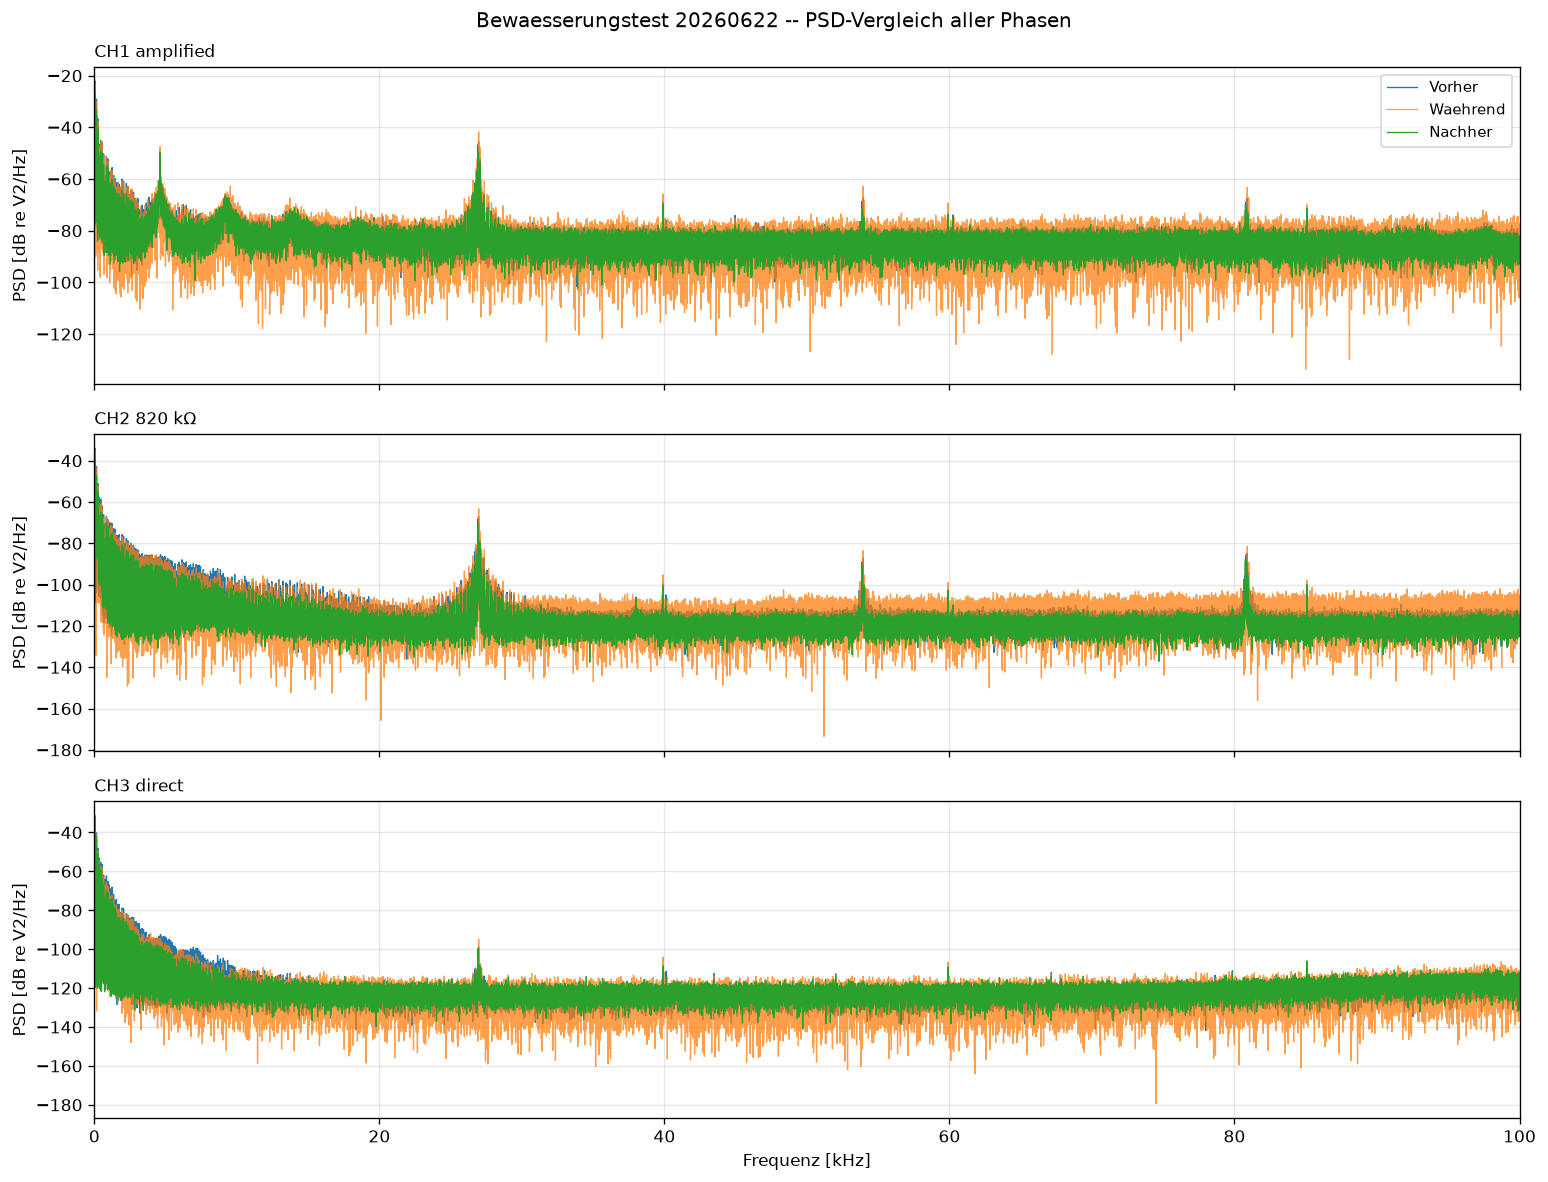

In [3]:
PHASE = {
    "Vorher":   (pre_data,      "tab:blue",   1.0),
    "Waehrend": (watering_data, "tab:orange", 0.75),
    "Nachher":  (post_data,     "tab:green",  1.0),
}

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, ch in zip(axes, (1, 2, 3)):
    for label, (data, color, alpha) in PHASE.items():
        freqs = data[ch]["frequencies"]
        m = (freqs >= 20) & (freqs <= MAX_FREQUENCY_HZ)
        ax.plot(freqs[m]/1e3,
                10*np.log10(np.maximum(data[ch]["mean_psd"][m], 1e-30)),
                color=color, alpha=alpha, lw=0.8, label=label)
    ax.set_ylabel("PSD [dB re V²/Hz]")
    ax.set_title(CHANNEL_LABELS[ch], loc="left", fontsize=10)
    if ch == 1:
        ax.legend(fontsize=9)
axes[-1].set_xlabel("Frequency [kHz]")
axes[-1].set_xlim(0, 100)
fig.suptitle(f"Watering test 20260622 — PSD comparison all phases", fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "spectra_comparison.png", bbox_inches="tight")
plt.show()

## 4. Difference spectrum: After minus Before

Frequency-resolved change in dB. Cross-channel agreement in the
same band increases the plausibility of a physical origin.


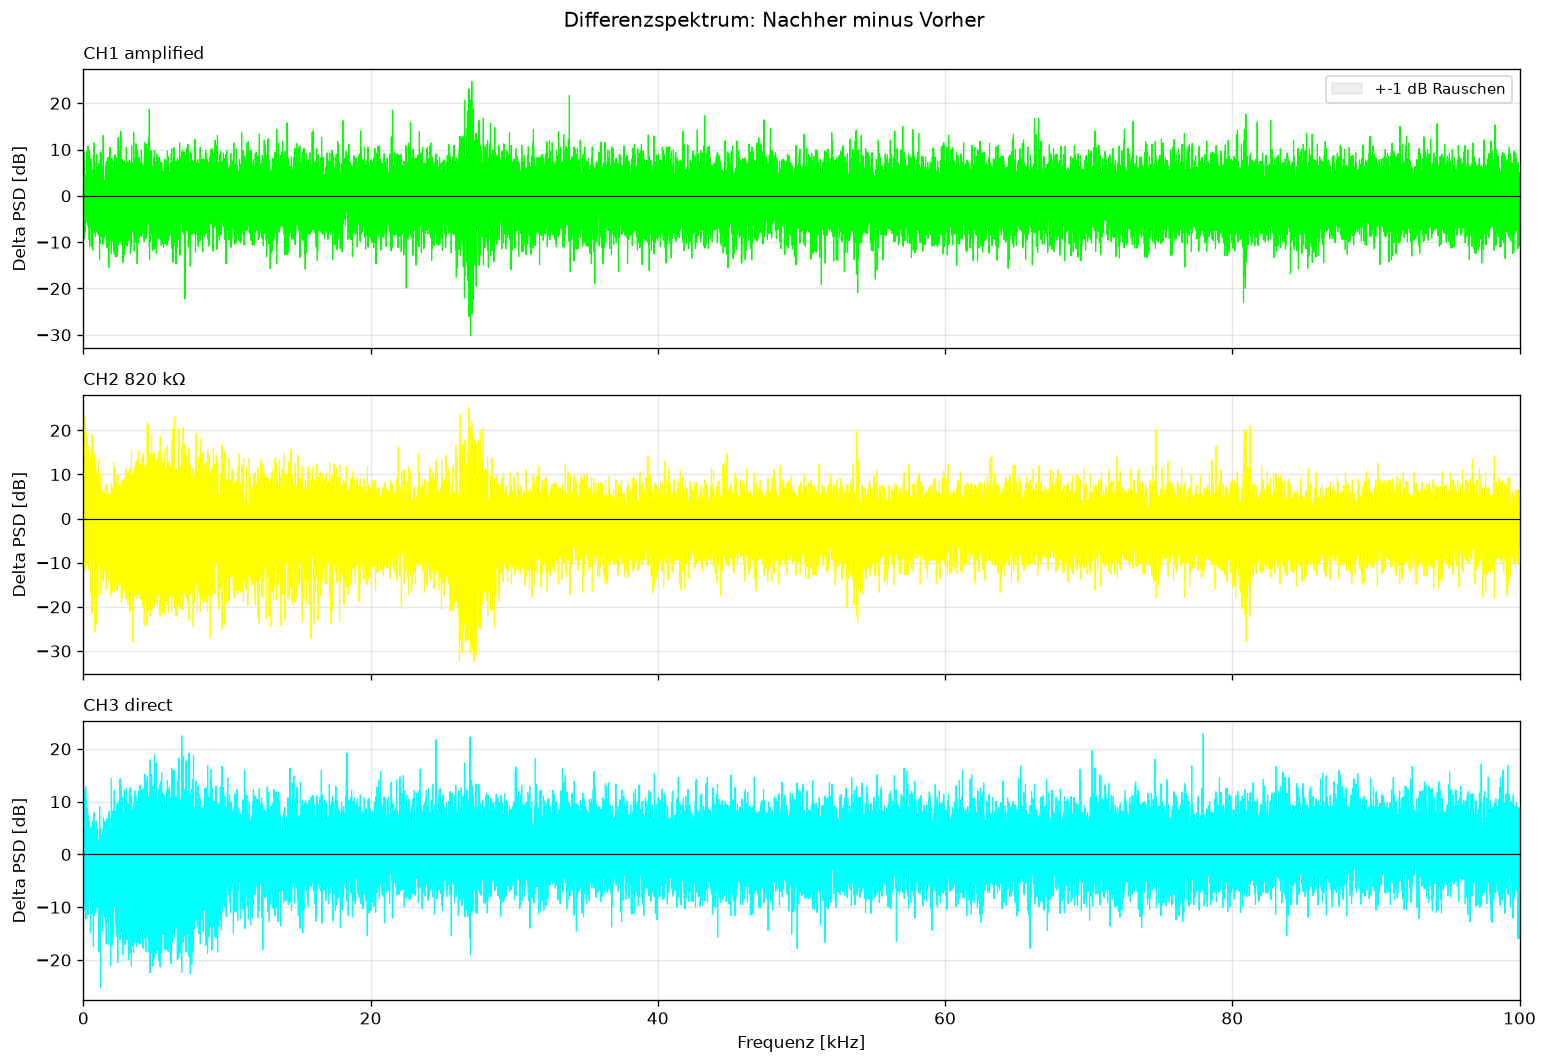

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, ch in zip(axes, (1, 2, 3)):
    freqs = pre_data[ch]["frequencies"]
    m = (freqs >= 20) & (freqs <= MAX_FREQUENCY_HZ)
    diff_db = 10 * np.log10(
        np.maximum(post_data[ch]["mean_psd"][m], 1e-30) /
        np.maximum(pre_data[ch]["mean_psd"][m], 1e-30)
    )
    ax.plot(freqs[m]/1e3, diff_db, color=CHANNEL_COLORS[ch], lw=0.7)
    ax.axhline(0, color="k", lw=0.7)
    ax.axhspan(-1, 1, color="gray", alpha=0.12, label="+-1 dB noise")
    ax.set_ylabel("Δ PSD [dB]")
    ax.set_title(CHANNEL_LABELS[ch], loc="left", fontsize=10)
    if ch == 1:
        ax.legend(fontsize=9)
axes[-1].set_xlabel("Frequency [kHz]")
axes[-1].set_xlim(0, 100)
fig.suptitle("Difference spectrum: After minus Before", fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "spectrum_difference.png", bbox_inches="tight")
plt.show()

## 5. Rolling-monitor events

`ContinuousFrequencyMonitor` continuously monitored drift, persistent peaks
and band-energy changes across all 14 frames.


In [5]:
events_path = run_dir / "rolling_events" / "events.jsonl"
events = [json.loads(l) for l in events_path.read_text().splitlines() if l.strip()]

by_type = {}
for e in events:
    by_type.setdefault(e["type"], []).append(e)

print(f"Total: {len(events)} detections in 14 frames")
for t, lst in sorted(by_type.items()):
    print(f"  {t}: {len(lst)}x")
print()
for e in events:
    et  = e["type"]
    seq = e.get("sequence", "?")
    ts  = e.get("timestamp_utc", "")[:19]
    if et == "cross_channel_band_energy_change":
        ch  = "+".join(f"CH{c}" for c in e["channels"])
        bnd = f"{e['band_low_hz']/1e3:.0f}-{e['band_high_hz']/1e3:.0f} kHz"
        cdb = ", ".join(f"CH{k}: {v:+.1f} dB" for k,v in e["change_db"].items())
        print(f"[{ts}] Seq {seq:3d} -- Band energy {bnd} on {ch}: {cdb}")
    elif et == "cross_channel_frequency_drift":
        ch  = "+".join(f"CH{c}" for c in e["channels"])
        print(f"[{ts}] Seq {seq:3d} -- Drift {e['start_frequency_hz']/1e3:.2f}->"
              f"{e['end_frequency_hz']/1e3:.2f} kHz  {e['slope_hz_per_second']:+.2f} Hz/s  {ch}")
    else:
        print(f"[{ts}] Seq {seq:3d} -- {et}")

Gesamt: 1 Erkennungen in 14 Frames
  cross_channel_band_energy_change: 1x

[2026-06-22T20:53:43] Seq  12 -- Bandenergie 0-5 kHz auf CH1+CH2: CH1: -4.5 dB, CH2: -5.0 dB


## 6. Zoom 0–6 kHz: event band

**Event Seq 12:** CH1 −4.5 dB / CH2 −5.0 dB in band 0–5 kHz (rolling
reference). The band contains the dominant common-mode tones at 0.87 / 2.19
/ 4.15 kHz (identified in NB02). The decrease on both independent
channels suggests a systemic effect.


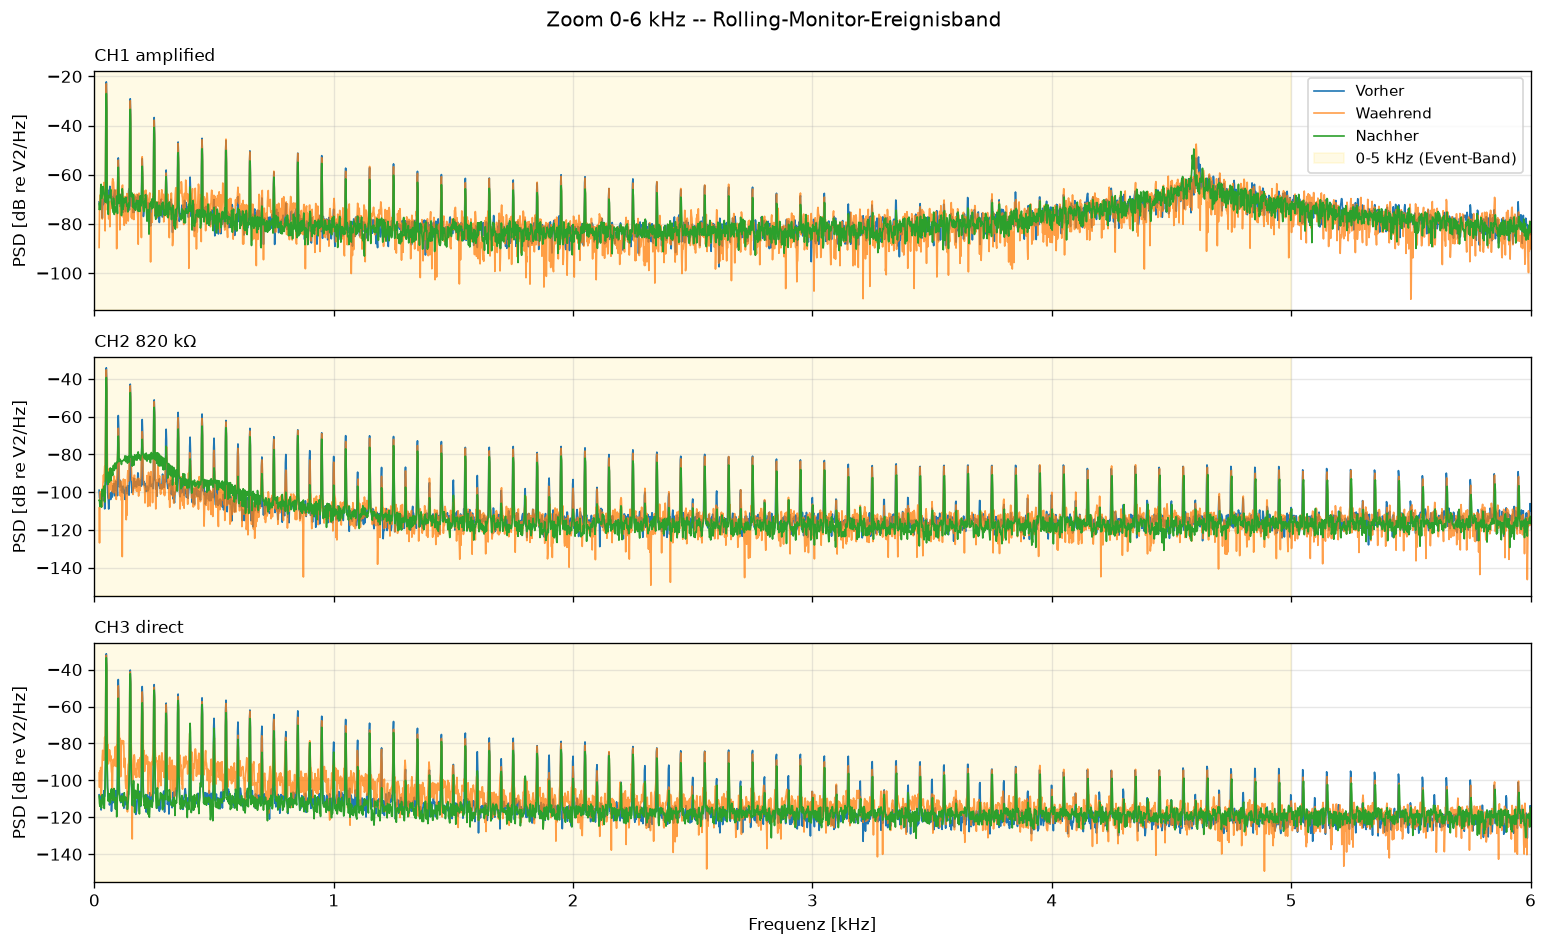

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, ch in zip(axes, (1, 2, 3)):
    for label, (data, color, alpha) in PHASE.items():
        freqs = data[ch]["frequencies"]
        m = (freqs >= 20) & (freqs <= 6000)
        ax.plot(freqs[m]/1e3,
                10*np.log10(np.maximum(data[ch]["mean_psd"][m], 1e-30)),
                color=color, alpha=alpha, lw=1.0, label=label)
    ax.axvspan(0, 5, color="gold", alpha=0.1, label="0–5 kHz (event band)")
    ax.set_ylabel("PSD [dB re V²/Hz]")
    ax.set_title(CHANNEL_LABELS[ch], loc="left", fontsize=10)
    if ch == 1:
        ax.legend(fontsize=9)
axes[-1].set_xlabel("Frequency [kHz]")
axes[-1].set_xlim(0, 6)
fig.suptitle("Zoom 0–6 kHz — rolling-monitor event band", fontsize=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "band_zoom_0_6khz.png", bbox_inches="tight")
plt.show()

## 7. Peak matching: frequency shifts Before → After

For each detected peak: median frequency (from distribution across frames),
shift in Hz, amplitude change, FDR-corrected Mann-Whitney-U p-value.

**Resolution limit:** Δf = 1.67 Hz/bin → 2 bins = 3.34 Hz.


In [7]:
matches = match_condition_peaks(pre_data, post_data)
if matches:
    df = pd.DataFrame([
        {"Channel":      f"CH{m['channel']}",
         "Before [kHz]": round(m["before_frequency_hz"]/1e3, 3),
         "After [kHz]":  round(m["after_frequency_hz"]/1e3, 3),
         "Δf [Hz]":      round(m["shift_hz"], 2),
         "> 2 bins":     "yes" if m["shift_exceeds_resolution"] else "",
         "Amp [dB]":     round(m["amplitude_change_db"], 1),
         "p_FDR":        round(m.get("p_value_fdr", 1.0), 4)}
        for m in matches
    ]).sort_values(["Kanal", "Vorher [kHz]"]).reset_index(drop=True)
    display(df)
    n_sig      = sum(1 for m in matches if m.get("p_value_fdr", 1.0) < 0.05)
    n_resolved = sum(1 for m in matches if m["shift_exceeds_resolution"])
    print(f"\n{len(matches)} matched peaks  |  {n_resolved} > 2 bins  |  {n_sig} FDR p<0.05")
else:
    print("No peak matches (too few frames or no common signal).")

,Kanal,Vorher [kHz],Nachher [kHz],Df [Hz],> 2 Bins,Amp [dB],p_FDR
0,CH1,0.050,0.050,0.02,,-4.8,NaN
1,CH1,0.050,0.050,0.02,,-4.0,NaN
2,CH1,0.250,0.250,0.00,,-4.6,NaN
3,CH1,1.250,0.952,-297.98,ja,-4.5,NaN
4,CH1,1.949,1.951,1.20,,-3.9,NaN
5,CH1,4.610,4.593,-16.15,ja,18.0,NaN
6,CH1,22.940,23.075,134.83,ja,0.3,NaN
7,CH1,26.937,26.933,-4.64,ja,-0.7,NaN
8,CH1,26.937,26.933,-4.64,ja,-4.2,NaN
9,CH1,27.337,27.333,-4.55,ja,-8.0,NaN



34 gematchte Peaks  |  18 > 2 Bins  |  0 FDR p<0,05


## 8. Scientific interpretation

### Observations
- **Rolling monitor:** 1 event — band-energy decrease 0–5 kHz on CH1 and CH2
  (−4.5 / −5.0 dB) at sequence 12 (post-watering). No drift, no new
  persistent peaks.
- **Difference spectrum:** Small changes in the 0–10 kHz range, no
  broadband activity burst.
- **Peak matching:** Shifts smaller than the spectral resolution limit
  → no statistically significant frequency drift in this single measurement.

### Explanations for the 0–5 kHz decrease (by plausibility)

1. **Common-mode from pump startup** — When the pump switches on, the mains
   impedance changes momentarily. This attenuates the coupling of mains
   harmonics (50 Hz × 1..100 = 0–5 kHz) into all channels simultaneously.
2. **Mechanical damping by water** — Water inflow into the xylem increases
   the acoustic admittance at low frequencies; the piezo measures less energy.
3. **Stochastic variation** — n=3 frames per phase, 11 min total duration;
   random drift not excluded without repetition.

### Conclusion
The run confirms that the entire pipeline (acquisition → rolling monitor
→ snapshot materialisation → analysis) runs correctly end-to-end.
Effect size: ~5 dB in the 0–5 kHz band.

**Next steps:**
1. ≥ 5 watering runs (confidence interval for effect size)
2. Control measurement: identical setup, sensor NOT on the plant
   → isolates pump common-mode from plant mechanics
3. Night/day comparison from continuous experiment (NB04)
